In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from itertools import combinations

In [2]:
# Set seed
rng = np.random.default_rng(1)

# Generate X and error term
n = 100
X = rng.normal(size=n)
epsilon = rng.normal(size=n)

# Define coefficients
beta0 = 1
beta1 = 2
beta2 = 3
beta3 = 4

# Generate Y
Y = beta0 + beta1*X + beta2*(X**2) + beta3*(X**3) + epsilon

print("First five X values:")
print(X[:5])

print("\nFirst five epsilon values:")
print(epsilon[:5])

First five X values:
[ 0.34558419  0.82161814  0.33043708 -1.30315723  0.90535587]

First five epsilon values:
[-0.65128101  0.8624448  -0.12559208  0.66915324  1.21884361]


In [3]:
data = pd.DataFrame()

for i in range(1, 11):
    data[f'X{i}'] = X**i

data['Y'] = Y

data.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,Y
0,0.345584,0.119428,0.041273,0.014263,0.004929,0.001703,0.000589,0.000203,0.000070,0.000024,1.563263
1,0.821618,0.675056,0.554639,0.455701,0.374412,0.307624,0.252749,0.207663,0.170620,0.140185,7.749404
2,0.330437,0.109189,0.036080,0.011922,0.003940,0.001302,0.000430,0.000142,0.000047,0.000016,2.007168
3,-1.303157,1.698219,-2.213046,2.883947,-3.758236,4.897573,-6.382308,8.317150,-10.838554,14.124341,-4.694689
4,0.905356,0.819669,0.742092,0.671858,0.608270,0.550701,0.498580,0.451393,0.408671,0.369993,9.456933


In [4]:
def forward_selection(data, response):

    remaining = list(data.columns)
    remaining.remove(response)

    selected = []
    current_score = np.inf

    while remaining:

        scores = []

        for candidate in remaining:

            predictors = selected + [candidate]

            X_model = sm.add_constant(data[predictors])

            model = sm.OLS(
                data[response],
                X_model
            ).fit()

            scores.append(
                (model.aic, candidate)
            )

        scores.sort()

        best_new_score, best_candidate = scores[0]

        if best_new_score < current_score:

            remaining.remove(best_candidate)

            selected.append(best_candidate)

            current_score = best_new_score

        else:
            break

    return selected

In [5]:
selected_forward = forward_selection(
    data,
    'Y'
)

print("Forward Selection Variables:")
print(selected_forward)

Forward Selection Variables:
['X3', 'X2', 'X1', 'X10']


In [6]:
X_forward = sm.add_constant(
    data[selected_forward]
)

forward_model = sm.OLS(
    data['Y'],
    X_forward
).fit()

print(forward_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                     3588.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          1.08e-102
Time:                        19:19:23   Log-Likelihood:                -135.03
No. Observations:                 100   AIC:                             280.1
Df Residuals:                      95   BIC:                             293.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0534      0.119      8.853      0.0

In [7]:
def backward_selection(data, response):

    selected = list(data.columns)

    selected.remove(response)

    current_score = float('inf')

    while len(selected) > 1:

        scores = []

        for candidate in selected:

            predictors = selected.copy()

            predictors.remove(candidate)

            X_model = sm.add_constant(
                data[predictors]
            )

            model = sm.OLS(
                data[response],
                X_model
            ).fit()

            scores.append(
                (model.aic,
                 candidate,
                 predictors)
            )

        scores.sort()

        best_new_score, candidate, best_predictors = scores[0]

        if best_new_score < current_score:

            current_score = best_new_score

            selected = best_predictors

        else:
            break

    return selected


In [8]:
selected_backward = backward_selection(
    data,
    'Y'
)

print("Backward Selection Variables:")
print(selected_backward)

Backward Selection Variables:
['X1', 'X2', 'X3', 'X8']


In [9]:
X_backward = sm.add_constant(
    data[selected_backward]
)

backward_model = sm.OLS(
    data['Y'],
    X_backward
).fit()

print(backward_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                     3559.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          1.59e-102
Time:                        19:20:35   Log-Likelihood:                -135.44
No. Observations:                 100   AIC:                             280.9
Df Residuals:                      95   BIC:                             293.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0684      0.121      8.808      0.0

In [10]:
predictors = [f'X{i}' for i in range(1,11)]

lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(
        cv=10,
        random_state=1,
        max_iter=10000
    ))
])

lasso.fit(
    data[predictors],
    data['Y']
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['X1','X2','X3',...,'X8','X9','X10']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [11]:
lasso_model = lasso.named_steps['lasso']

print("Optimal Lambda:")
print(lasso_model.alpha_)

Optimal Lambda:
0.012632559544032189


In [15]:
coef_df = pd.DataFrame({
    'Predictor': predictors,
    'Coefficient': lasso_model.coef_
})

print(coef_df)

  Predictor  Coefficient
0        X1     1.531802
1        X2     3.259597
2        X3    11.821227
3        X4     0.000000
4        X5     0.000000
5        X6     0.000000
6        X7     0.000000
7        X8     0.000000
8        X9    -0.000000
9       X10     0.539365


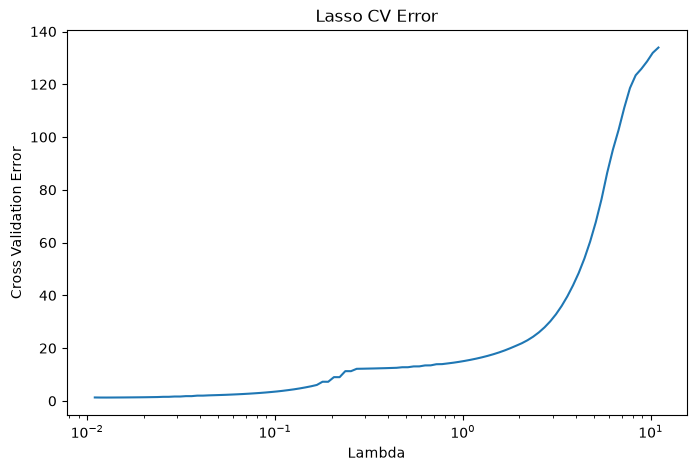

In [12]:
mean_mse = lasso_model.mse_path_.mean(axis=1)

plt.figure(figsize=(8,5))

plt.plot(
    lasso_model.alphas_,
    mean_mse
)

plt.xscale('log')

plt.xlabel('Lambda')

plt.ylabel('Cross Validation Error')

plt.title('Lasso CV Error')

plt.show()

In [13]:
Y2 = 1 + 5*(X**7) + epsilon

data2 = pd.DataFrame()

for i in range(1,11):
    data2[f'X{i}'] = X**i

data2['Y'] = Y2

In [16]:
selected_forward2 = forward_selection(
    data2,
    'Y'
)

print(selected_forward2)

['X7', 'X9', 'X4']


In [17]:
lasso.fit(
    data2[predictors],
    data2['Y']
)

lasso_model2 = lasso.named_steps['lasso']

coef_df2 = pd.DataFrame({
    'Predictor': predictors,
    'Coefficient': lasso_model2.coef_
})

print(coef_df2)

  Predictor  Coefficient
0        X1    -0.000000
1        X2    -0.000000
2        X3     0.000000
3        X4    -0.000000
4        X5    31.446632
5        X6    -0.000000
6        X7   490.694475
7        X8    -0.000000
8        X9    47.909374
9       X10    -0.000000
